In [272]:
import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import v2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [273]:
# Import Data
df_cases = pd.read_csv("../data/bangkok_dengue_1993_2023.csv")
df_weather = pd.read_csv("../data/weekly_data.csv")

# Format to datetime
df_cases["calendar_start_date"] = pd.to_datetime(df_cases["calendar_start_date"])
df_cases["calendar_end_date"] = pd.to_datetime(df_cases["calendar_end_date"])
df_cases = df_cases.sort_values("calendar_start_date")

df_weather["valid_time"] = pd.to_datetime(df_weather["valid_time"])
df_weather = df_weather.sort_values("valid_time")

# Create a monthly matching column in each dataframe
df_weather["month"] = df_weather["valid_time"].dt.to_period("M")
df_cases["month"] = df_cases["calendar_end_date"].dt.to_period("M")

# Merge monthly dengue totals onto each weekly weather observation
df_combined = df_weather.merge(
    df_cases[["month", "dengue_total"]],
    on="month",
    how="left"
)

df_combined = df_combined.sort_values("valid_time").reset_index(drop=True)
df_combined = df_combined.drop(columns=["month", "latitude", "longitude"])

weather_cols = [
    col for col in df_combined.columns
    if col not in ["valid_time", "dengue_total"]
]

# Monthly dengue case counts
monthly_cases = (
    df_combined.assign(
        month=df_combined["valid_time"].dt.to_period("M")
    )
    .drop_duplicates("month")
    .dropna()
    .set_index("month")["dengue_total"]
    .sort_index()
)

# Input columns: weather + historical dengue cases
input_cols = weather_cols + ["dengue_total"]

df_combined.head(10)

,valid_time,d2m,t2m,tp,dengue_total
0,1993-01-03,294.047634,300.266561,0.000196,194.0
1,1993-01-10,292.710655,300.161210,0.000026,194.0
2,1993-01-17,294.799441,300.824044,0.001966,194.0
3,1993-01-24,294.909541,300.735656,0.006118,194.0
4,1993-01-31,286.753935,296.970963,0.002281,194.0
5,1993-02-07,287.174452,298.823327,0.000000,159.0
6,1993-02-14,294.459790,300.398823,0.000630,159.0
7,1993-02-21,294.526880,300.922179,0.002067,159.0
8,1993-02-28,294.815038,301.672267,0.000342,159.0
9,1993-03-07,296.358405,302.082197,0.005665,175.0


We will create a custom Pytorch Dataset that generates the appropriate input and target vectors.  For a window beginning at week $t$, we'll observe 24 weeks of historical weather data and historical Dengue cases. I.e.
$$
X_t = 
\begin{bmatrix}
    W_t & D_t \\
    W_{t+1} & D_{t+1} \\
    \vdots & \vdots \\
    W_{t+23} & D_{t+23}
\end{bmatrix}
$$
where $W_t$ represents the weather variables, and $D_t$ represents the historical monthly Dengue count.  The target is 
$$
Y_t = \begin{bmatrix}
    D_{m+1} & \cdots & D_{m+6}
\end{bmatrix}
$$
where $m$ is the month containing the final week of the input window. 

In [274]:
class DengueDataset(Dataset):

    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

    def __repr__(self):
        return f"DengueDataset(X={self.X.shape}, Y={self.Y.shape})" 

In [275]:
X = []
Y = []

window_size = 24
forecast_months = 6

for i in range(len(df_combined) - window_size + 1):

    # 24 weeks of historical data
    window = df_combined.iloc[i:i + window_size]

    # Last month represented in the input window
    last_month = window["valid_time"].iloc[-1].to_period("M")

    # The following six calendar months
    target_periods = pd.period_range(
        start=last_month + 1,
        periods=forecast_months,
        freq="M"
    )

    # Skip samples for which all six target months aren't available
    if not target_periods.isin(monthly_cases.index).all():
        continue

    # Weather + historical dengue cases
    x = window[input_cols].to_numpy(dtype=np.float32)

    # Six monthly dengue case counts
    y = monthly_cases.loc[target_periods].to_numpy(dtype=np.float32)

    X.append(x)
    Y.append(y)

X = np.array(X)
Y = np.array(Y)

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (1516, 24, 4)
Y shape: (1516, 6)


Now we can split the data into training and testing sets.  We will tentatively use 80% for the training and 20% for the testing.  

Note that we are splitting based on the *target dates*, not the input dates, allowing the model to use historical observations from before the testing period to forecast into the testing period. 

In [276]:
# Parameters
window_size = 24
forecast_months = 6
train_fraction = 0.8

# Determine chronological cutoff
all_months = monthly_cases.index.sort_values()
cutoff = all_months[int(train_fraction * len(all_months))]


# Initialize arrays
X_train, Y_train = [], []
X_test, Y_test = [], []
test_target_months = []

# Now perform the split
for i in range(len(df_combined) - window_size + 1):

    # 24 weeks of historical data
    window = df_combined.iloc[i:i + window_size]

    # Last month represented in the input window
    last_month = window["valid_time"].iloc[-1].to_period("M")

    # The following six calendar months
    target_periods = pd.period_range(
        start=last_month + 1,
        periods=forecast_months,
        freq="M"
    )

    # Skip samples for which all six target months aren't available
    if not target_periods.isin(monthly_cases.index).all():
        continue

    # Weather + historical dengue cases
    x = window[input_cols].to_numpy(dtype=np.float32)

    # Six monthly dengue case counts
    y = monthly_cases.loc[target_periods].to_numpy(dtype=np.float32)
    
    if target_periods[-1] < cutoff:
        X_train.append(x)
        Y_train.append(y)
    else:
        X_test.append(x)
        Y_test.append(y)
        test_target_months.append(target_periods)

X_train = np.array(X_train)
Y_train = np.array(Y_train)
X_test = np.array(X_test)
Y_test = np.array(Y_test)

test_dates = pd.PeriodIndex(
    [month for periods in test_target_months for month in periods],
    freq="M"
)

print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)
print("X_test shape:", X_test.shape)
print("Y_test shape:", Y_test.shape)

X_train shape: (1203, 24, 4)
Y_train shape: (1203, 6)
X_test shape: (313, 24, 4)
Y_test shape: (313, 6)


Now we can standardize the training and test sets, and use them to create our custom Dataset, and use those to create DataLoaders. 

In [277]:
# Standardize X using training data
x_mean = X_train.mean(axis=(0, 1), keepdims=True)
x_std = X_train.std(axis=(0, 1), keepdims=True) + 1e-8

X_train = (X_train - x_mean) / x_std
X_test = (X_test - x_mean) / x_std

# Standardize Y using training data
y_mean = Y_train.mean()
y_std = Y_train.std() + 1e-8

Y_train = (Y_train - y_mean) / y_std
Y_test = (Y_test - y_mean) / y_std

# Create datasets
train_dataset = DengueDataset(X_train, Y_train)
test_dataset = DengueDataset(X_test, Y_test)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print(repr(train_dataset))
print(repr(test_dataset))

DengueDataset(X=torch.Size([1203, 24, 4]), Y=torch.Size([1203, 6]))
DengueDataset(X=torch.Size([313, 24, 4]), Y=torch.Size([313, 6]))


In [278]:
# Choose the device for training the neural network
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


We'll now define the neural network architecture.  This class takes as three parameters. First is `nfeatures`, which is the number of input features to the neural network.  In our case, this will be the 24 weekly observations of the 4 parameters `d2m`, `t2m`, `tp`, and `dengue_total`, so 96 total input values.  Note that `dengue_total` will be replicated for weeks which are in the same month.  The second parameter is `nforecast`, which is our forecast horizon, which in our case will be six months.  Finally there is `hiddenlayersizes`, which just specifies the sizes of the hidden layers between the input and the output.  

In [279]:
# Define the neural network architecture
class NeuralNetwork(nn.Module):
    def __init__(self, nfeatures, nforecast, hiddenlayersizes):
        nhiddenlayers = len(hiddenlayersizes)
        super().__init__()
        self.flatten = nn.Flatten()
        layers = []
        input_dim = nfeatures
        for hidden_dim in hiddenlayersizes:
            layers.append(nn.Linear(input_dim, hidden_dim))
            layers.append(nn.ReLU())
            input_dim = hidden_dim
        layers.append(nn.Linear(input_dim, nforecast))
        self.linear_relu_stack = nn.Sequential(*layers)

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

For this jupyter notebook we'll use hidden layer sizes of 128, 64, and 32.  The loss function is computed using PyTorch's built in `MSELoss()` function, and we'll use the `optim.Adam()` algorith to perform stochastic gradient descent with a learing rate of 0.001.  Of course, these are all hyperparameters which can be adjusted later. 

In [280]:
# Dimensions
nfeatures = 24 * X_train.shape[2]
nforecast = Y_train.shape[1]

hiddenlayersizes = [128, 64, 32]

# Initialize model
model = NeuralNetwork(
    nfeatures= nfeatures,
    nforecast=nforecast,
    hiddenlayersizes=hiddenlayersizes
)

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=96, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=6, bias=True)
  )
)


We now train the nerual network defined above using our custom Datasets and DataLoaders, and for each iteration evaluate the running loss against the training data and the testing data, and are saved in the arrays `train_losses` and `test_losses` respectively. The model is trained for 500 epochs, and the progress is printed for every 50th epoch. 

In [281]:
# Hyperparameters
num_epochs = 500

train_losses = []
test_losses = []

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, targets)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # --------------------
    # Testing
    # --------------------
    model.eval()
    running_loss = 0.0

    with torch.no_grad():

        for inputs, targets in test_loader:

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)

    epoch_test_loss = running_loss / len(test_loader.dataset)
    test_losses.append(epoch_test_loss)

    # Print progress
    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Train Loss: {epoch_train_loss:.6f}, "
            f"Test Loss: {epoch_test_loss:.6f}"
        )

Epoch [50/500], Train Loss: 0.024292, Test Loss: 0.419658
Epoch [100/500], Train Loss: 0.019450, Test Loss: 0.422492
Epoch [150/500], Train Loss: 0.005999, Test Loss: 0.428565
Epoch [200/500], Train Loss: 0.009531, Test Loss: 0.423380
Epoch [250/500], Train Loss: 0.004120, Test Loss: 0.402359
Epoch [300/500], Train Loss: 0.001833, Test Loss: 0.410105
Epoch [350/500], Train Loss: 0.002899, Test Loss: 0.404304
Epoch [400/500], Train Loss: 0.001676, Test Loss: 0.395459
Epoch [450/500], Train Loss: 0.015932, Test Loss: 0.401620
Epoch [500/500], Train Loss: 0.001187, Test Loss: 0.393171


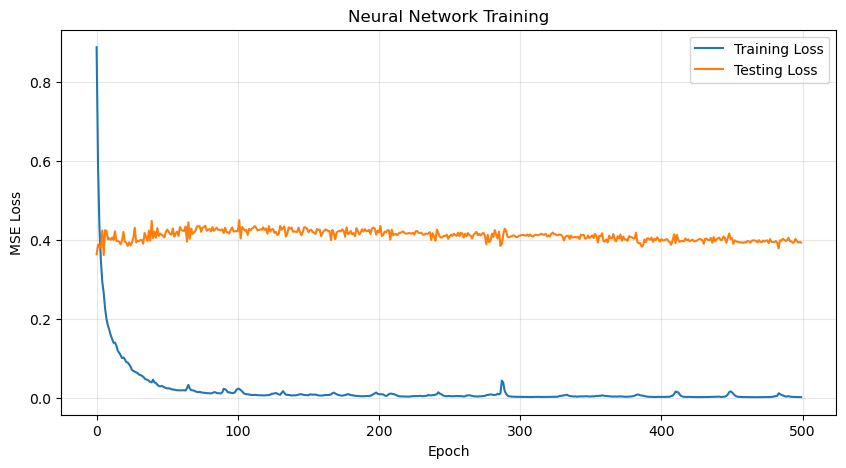

In [282]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(test_losses, label="Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Neural Network Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Above we can see how the MSE loss evolves over the course of training.  The training loss decays quickly, while the testing loss remains relatively static, although does go down slightly.  The variance of the testing loss also empirically seems to decay with training. 

Below are some diagnostics, including the MSE of all of the predictions against their actual counterparts.  There is also a plot of the actual cases against the average of the forecasts, in months where there are multiple forecasts.  

In [283]:
model.eval()

with torch.no_grad():
    Y_pred = model(torch.tensor(X_test, dtype=torch.float32)).numpy()

# Reverse target standardization, if you standardized Y
Y_pred = Y_pred * y_std + y_mean
Y_actual = Y_test * y_std + y_mean

# Calculate and print the mean squared error
mse = ((Y_pred - Y_actual) ** 2).mean()
print("Mean Squared Error:", mse)

Mean Squared Error: 84497.47


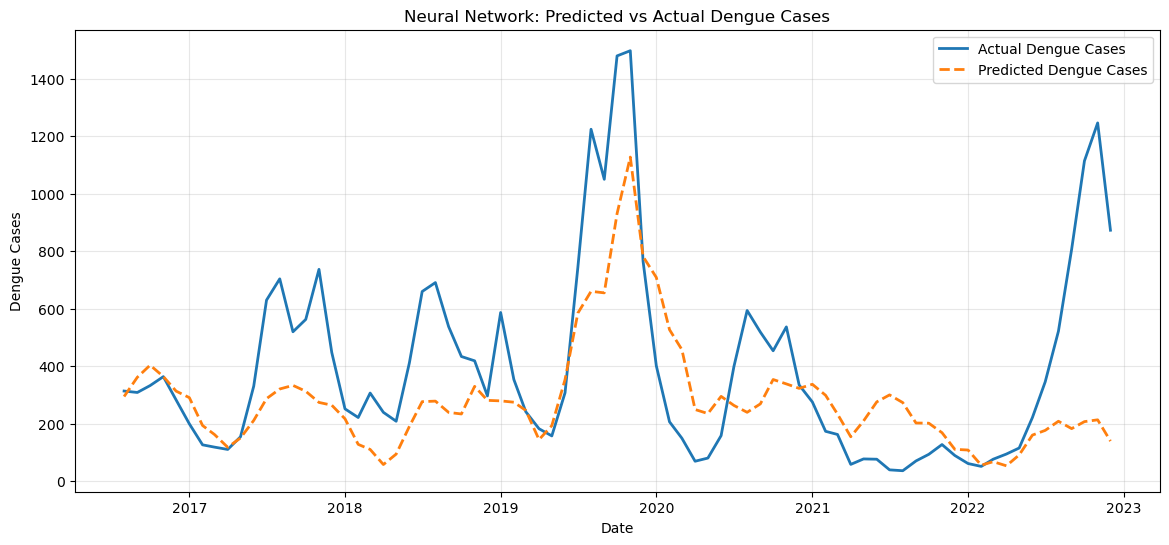

In [285]:
# Flatten predictions and actual values
predicted_flat = Y_pred.flatten()
actual_flat = Y_actual.flatten()

# Create dataframe
forecast_df = pd.DataFrame({
    "date": test_dates.to_timestamp(),
    "predicted": predicted_flat,
    "actual": actual_flat
})

# Average predictions for months with multiple forecasts
plot_df = forecast_df.groupby("date").agg({
    "predicted": "mean",
    "actual": "first"
}).reset_index()

# Plot
plt.figure(figsize=(14, 6))

plt.plot(
    plot_df["date"],
    plot_df["actual"],
    label="Actual Dengue Cases",
    linewidth=2
)

plt.plot(
    plot_df["date"],
    plot_df["predicted"],
    label="Predicted Dengue Cases",
    linewidth=2,
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Dengue Cases")
plt.title("Neural Network: Predicted vs Actual Dengue Cases")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Now Let's use the most recent 24 weeks in our dataset to make a prediction for future Dengue cases. 

In [302]:
# Get the most recent 18 weeks
recent_data = df_combined.sort_values("valid_time").tail(24 + 1).iloc[:-1]

# Extract the same input features used during training
x_new = recent_data[input_cols].to_numpy(dtype=np.float32)

# Add batch dimension
x_new = np.expand_dims(x_new, axis=0)

# standardize the input
x_new = (x_new - x_mean) / x_std

In [306]:
model.eval()

with torch.no_grad():

    x_tensor = torch.tensor(x_new, dtype=torch.float32)

    prediction = model(x_tensor).numpy()

# Reverse target standardization
prediction = prediction * y_std + y_mean

# Extract six predictions
prediction = prediction.flatten()

# Last month represented in the historical input
last_month = recent_data["valid_time"].iloc[-1].to_period("M")

# Next six months
forecast_dates = pd.period_range(
    start=last_month + 1,
    periods=6,
    freq="M"
)

# Create forecast dataframe
forecast_df = pd.DataFrame({
    "date": forecast_dates.to_timestamp(),
    "predicted_dengue": prediction
})

print(forecast_df)

        date  predicted_dengue
0 2023-01-01        471.926697
1 2023-02-01        413.707214
2 2023-03-01        413.797180
3 2023-04-01        299.562897
4 2023-05-01        758.190308
5 2023-06-01        928.827393


And we can plot the forecast to see if our results make any sense. 

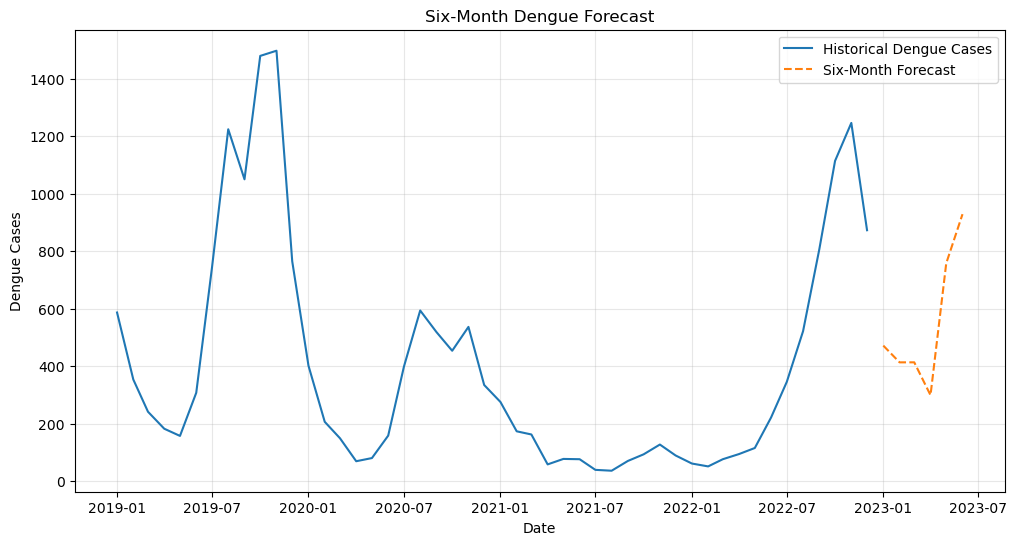

In [307]:
# Historical monthly cases
historical = monthly_cases.tail(48).copy()

plt.figure(figsize=(12, 6))

plt.plot(
    historical.index.to_timestamp(),
    historical.values,
    label="Historical Dengue Cases"
)

plt.plot(
    forecast_df["date"],
    forecast_df["predicted_dengue"],
    linestyle="--",
    label="Six-Month Forecast"
)

plt.xlabel("Date")
plt.ylabel("Dengue Cases")
plt.title("Six-Month Dengue Forecast")
plt.legend()
plt.grid(alpha=0.3)
plt.show()